# Data Analysis

The purpose of this notebook is to analyse our data and create plots.

_index work in progress_
**Index**

- libraries
- settings
- import data
- 01 - MOVEMENT & MODES
- 02 - CAMERA MOVEMENT & MODES
- 03 - CLUSTERING MOVEMENT & CAMERA
    - plot settings
    - create dataframe
    - camera movement histogram
    - 3d plot
    - 2d scatter of 3d plot
    - scaling
    - k-means
    - choosing k
    - outliers


## libraries

In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


## settings

In [2]:
DATA_DIR = Path("../data")
EXPORT_DIR = DATA_DIR / "notebooks_exports"

WIDE_TABLE_PATH = EXPORT_DIR / "wide_table.csv"
SPEED_TO_BLOCK_PER_CLICK_PATH = EXPORT_DIR / "speed_to_block_per_click.csv"
MCPLAYHD_CONCEPT_PATH = EXPORT_DIR / "mcplayhd_concept.csv"

RANDOM_SEED = 42

DEFAULT_MODE_COLOR = "grey"
MODE_COLORS = {
    "EXTRASHORT": "C0",
    "SHORT": "C1",
    "NORMAL": "C2",
    "LONG": "C3",
    "INCLINEDSHORT": "C4",
    "INCLINED": "C5",
    "ONESTACK": "C6",
}

## import data

In [3]:
df_wide = pd.read_csv(WIDE_TABLE_PATH)
df_speed_to_block_per_click = pd.read_csv(SPEED_TO_BLOCK_PER_CLICK_PATH)
df_mcplayhd_concept = pd.read_csv(MCPLAYHD_CONCEPT_PATH)

print(f"wide: {df_wide.shape}")
print(f"speed to bpc: {df_speed_to_block_per_click.shape}")
print(f"mcplayhd: {df_mcplayhd_concept.shape}")

wide: (9419, 361)
speed to bpc: (9361, 5)
mcplayhd: (9419, 547)


## 01 - movement & modes

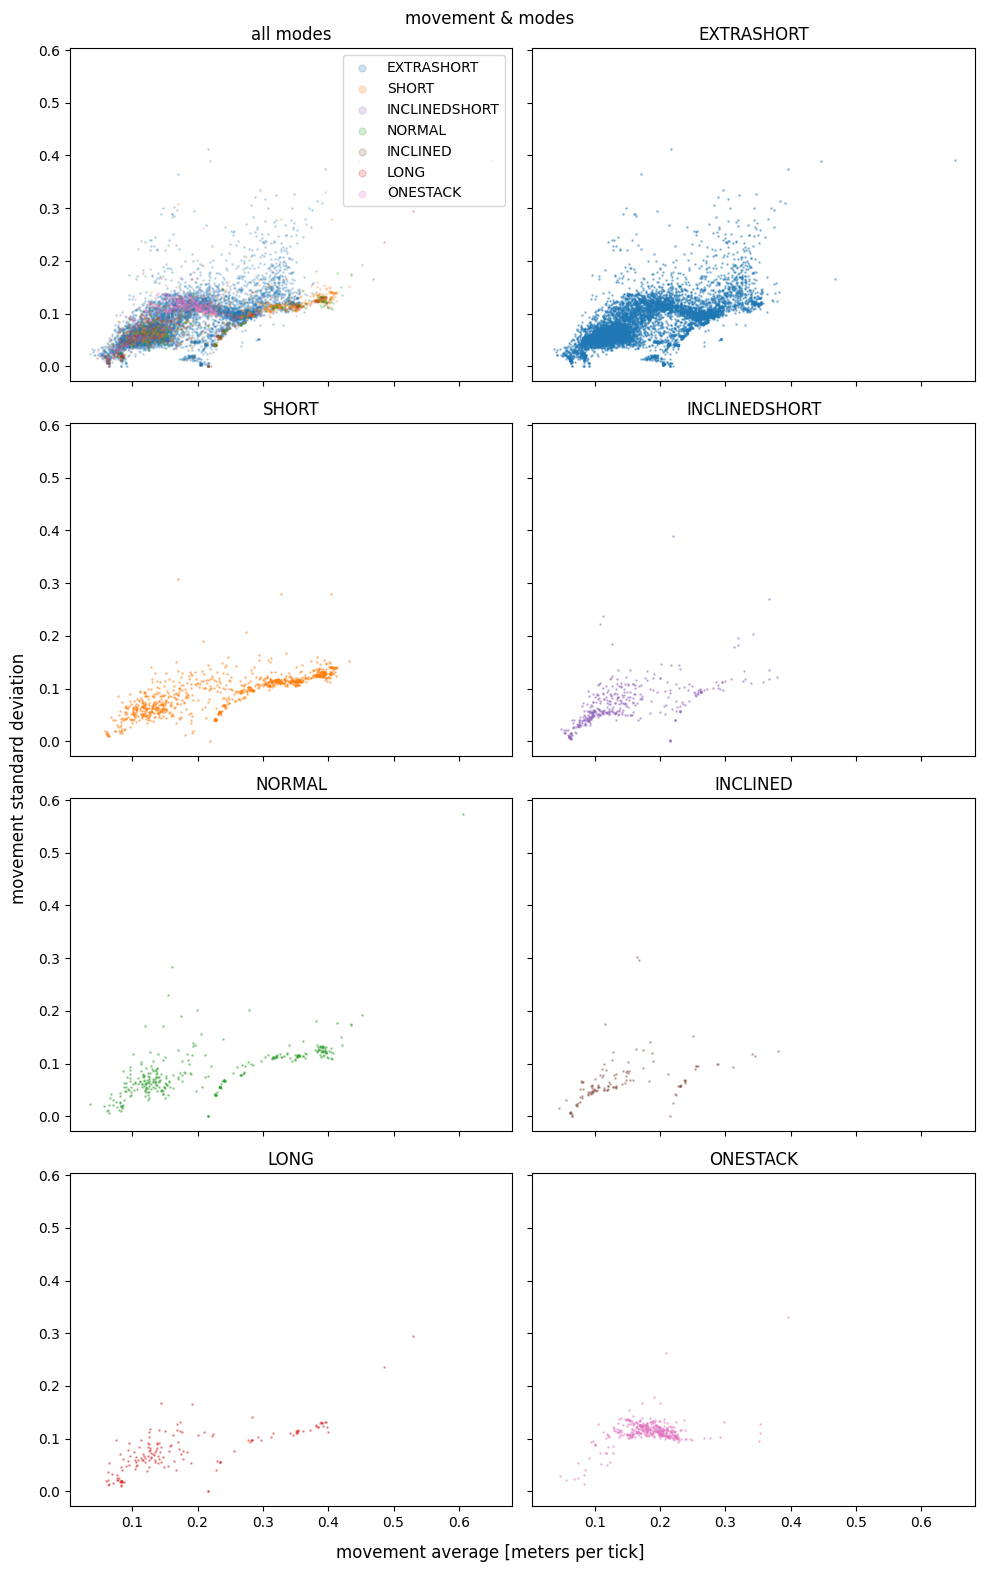

In [4]:
modes_list = df_wide["fastBuilderMode"].unique()
graph_rows = math.ceil((len(modes_list)+1) / 2)

fig, axes = plt.subplots(graph_rows, 2, figsize=(10, 4* graph_rows), sharex=True, sharey=True)
axes = axes.flatten()

movement_columns = df_wide.columns.str.startswith("movement_")
movement_array = df_wide.loc[:, movement_columns].to_numpy()
movement_avg = movement_array.mean(axis=1)
movement_std = movement_array.std(axis=1)

for mode in modes_list:
    is_mode = (df_wide["fastBuilderMode"] == mode).to_numpy()
    axes[0].scatter(movement_avg[is_mode], movement_std[is_mode], s=1.0, alpha=0.2, label=mode, color=MODE_COLORS.get(mode, DEFAULT_MODE_COLOR))

for ax, mode in zip(axes[1:], modes_list):
    is_mode = (df_wide["fastBuilderMode"] == mode).to_numpy()
    ax.scatter(movement_avg[is_mode], movement_std[is_mode], s=0.8, alpha=0.4, color=MODE_COLORS.get(mode, DEFAULT_MODE_COLOR))
    ax.set_title(mode)

axes[0].legend(markerscale=5)
axes[0].set_title("all modes")
fig.supxlabel("movement average [meters per tick]")
fig.supylabel("movement standard deviation")
fig.suptitle("movement & modes")
fig.tight_layout()

plt.show()

## 02 - camera movement & modes

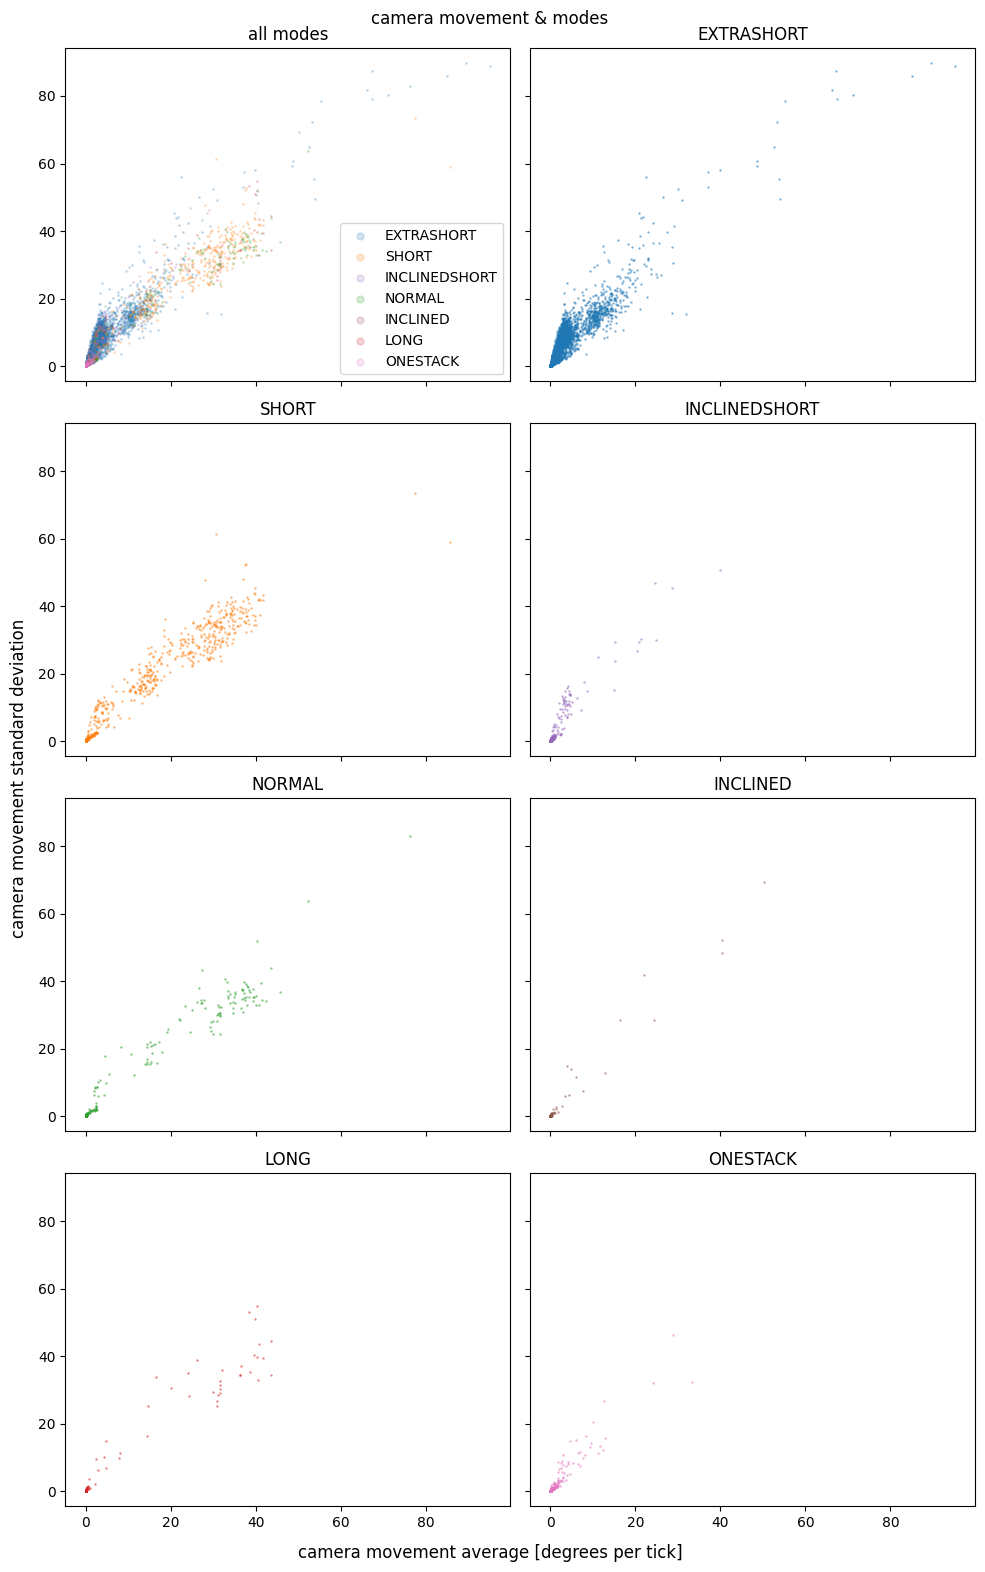

In [5]:
modes_list = df_wide["fastBuilderMode"].unique()
graph_rows = math.ceil((len(modes_list)+1) / 2)

fig, axes = plt.subplots(graph_rows, 2, figsize=(10, 4* graph_rows), sharex=True, sharey=True)
axes = axes.flatten()

yaw_columns = df_wide.columns.str.startswith("yaw_change_")
pitch_columns = df_wide.columns.str.startswith("pitch_change_")
yaw_array = df_wide.loc[:, yaw_columns].to_numpy()
pitch_array = df_wide.loc[:, pitch_columns].to_numpy()

turn_array = np.hypot(yaw_array, pitch_array)
turn_avg = turn_array.mean(axis=1)
turn_std = turn_array.std(axis=1)

for mode in modes_list:
    is_mode = (df_wide["fastBuilderMode"] == mode).to_numpy()
    axes[0].scatter(turn_avg[is_mode], turn_std[is_mode], s=1.0, alpha=0.2, label=mode, color=MODE_COLORS.get(mode, DEFAULT_MODE_COLOR))

for ax, mode in zip(axes[1:], modes_list):
    is_mode = (df_wide["fastBuilderMode"] == mode).to_numpy()
    ax.scatter(turn_avg[is_mode], turn_std[is_mode], s=0.8, alpha=0.4, color=MODE_COLORS.get(mode, DEFAULT_MODE_COLOR))
    ax.set_title(mode)

axes[0].legend(markerscale=5)
axes[0].set_title("all modes")
fig.supxlabel("camera movement average [degrees per tick]")
fig.supylabel("camera movement standard deviation")
fig.suptitle("camera movement & modes")
fig.tight_layout()

plt.show()

## 03 - clustering movement & camera


#### plot settings

In [6]:
CLUSTER_COUNT = 5
CLUSTER_FEATURES = ["movement_avg", "movement_std", "turn_avg_log"]

OUTLIER_PERCENTILE = 99

#### create dataframe

In [7]:
df_clustering = pd.DataFrame({
    "idAnonymous": df_wide["idAnonymous"],
    "fastBuilderMode": df_wide["fastBuilderMode"],
    "movement_avg": movement_avg,
    "movement_std": movement_std,
    "turn_avg_log": np.log1p(turn_avg),
})

#### camera movement histogram

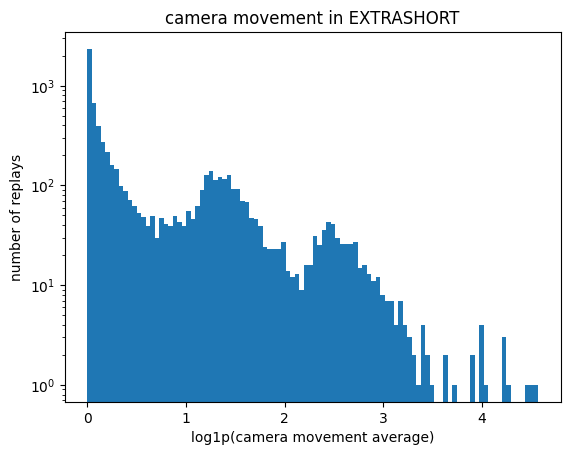

In [8]:
is_mode = df_clustering["fastBuilderMode"] == "EXTRASHORT"
df_clustering_extrashort = df_clustering[is_mode]

plt.hist(df_clustering_extrashort["turn_avg_log"], bins=100)
plt.xlabel("log1p(camera movement average)")
plt.yscale("log")
plt.ylabel("number of replays")
plt.title("camera movement in EXTRASHORT")
plt.show()

#### 3d plot


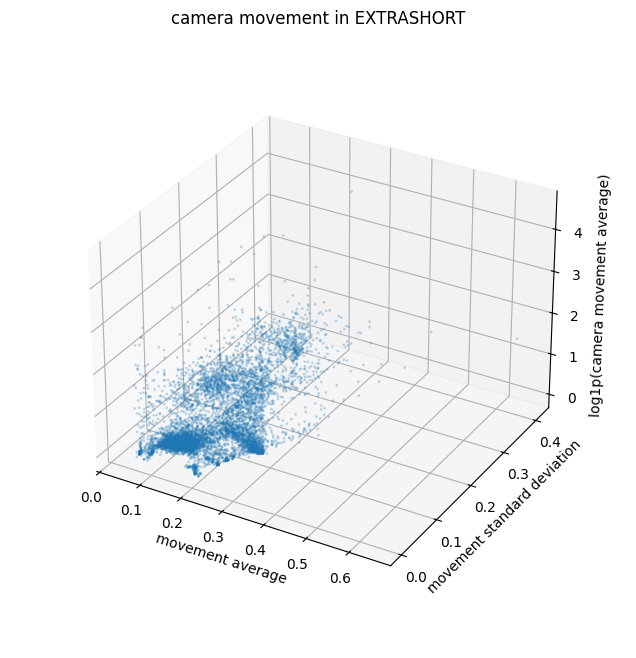

In [9]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection="3d")

ax.scatter(
    df_clustering_extrashort["movement_avg"],
    df_clustering_extrashort["movement_std"],
    df_clustering_extrashort["turn_avg_log"],
    s=1.2,
    alpha=0.2
)
ax.set_xlabel("movement average")
ax.set_ylabel("movement standard deviation")
ax.set_zlabel("log1p(camera movement average)")
ax.set_title("camera movement in EXTRASHORT")
ax.set_box_aspect(None, zoom=0.85)
plt.show()


#### 2d scatter of 3d plot

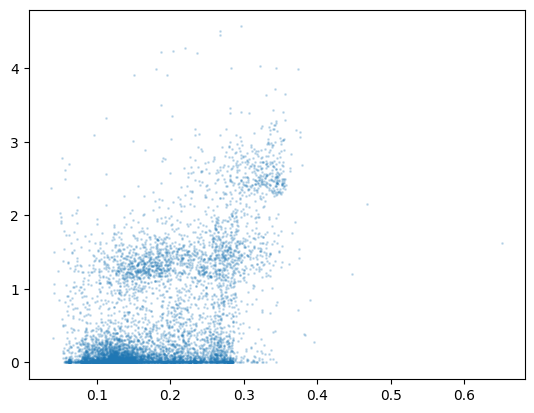

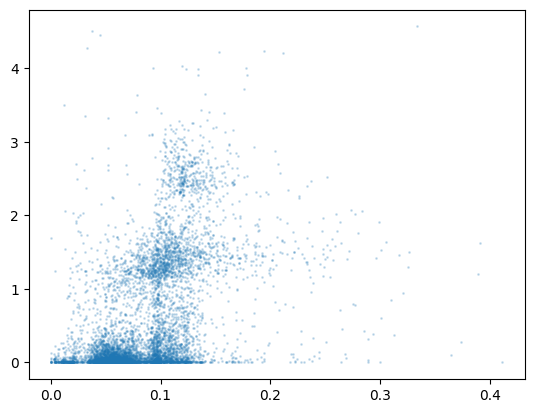

In [10]:
plt.scatter(df_clustering_extrashort["movement_avg"], df_clustering_extrashort["turn_avg_log"], s=1.0, alpha=0.2)
plt.show()
plt.scatter(df_clustering_extrashort["movement_std"], df_clustering_extrashort["turn_avg_log"], s=1.0, alpha=0.2)
plt.show()


#### scaling

In [11]:
features_extrashort = df_clustering_extrashort[CLUSTER_FEATURES]
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_extrashort)

print(features_scaled.shape, features_scaled.mean(axis=0))
print(features_scaled.std(axis=0))

(7095, 3) [ 1.71251315e-16 -6.70984684e-17  5.20764232e-17]
[1. 1. 1.]


#### k-means clustering

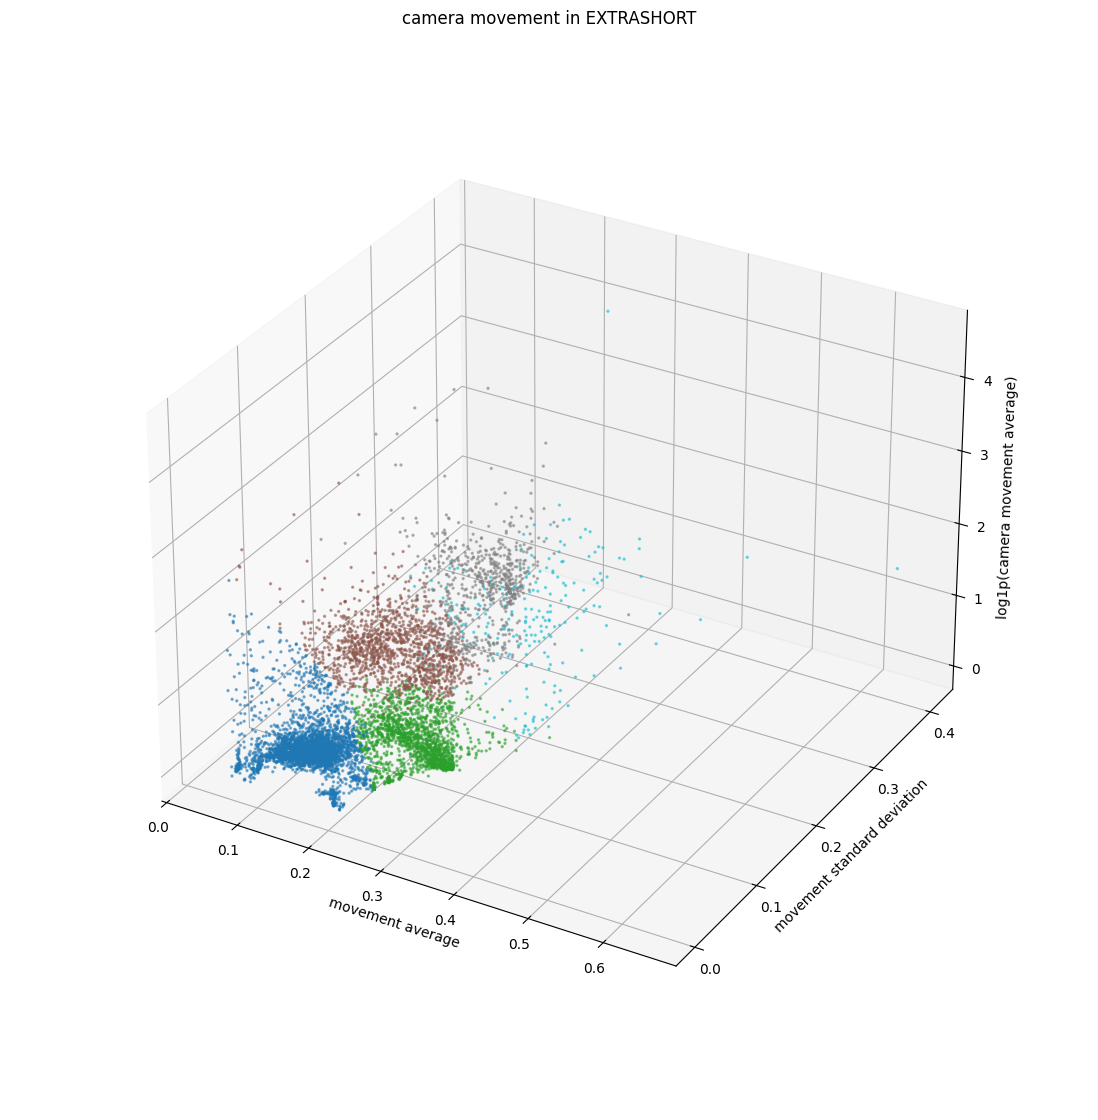

In [12]:
kmeans = KMeans(n_clusters=CLUSTER_COUNT, random_state=RANDOM_SEED)
cluster_labels = kmeans.fit_predict(features_scaled)

fig = plt.figure(figsize=(18, 14))
ax = fig.add_subplot(projection="3d")

ax.scatter(
    df_clustering_extrashort["movement_avg"],
    df_clustering_extrashort["movement_std"],
    df_clustering_extrashort["turn_avg_log"],
    c=cluster_labels,
    cmap="tab10",
    s=2.0,
    alpha=0.5
)
ax.set_xlabel("movement average")
ax.set_ylabel("movement standard deviation")
ax.set_zlabel("log1p(camera movement average)")
ax.set_title("camera movement in EXTRASHORT")
ax.set_box_aspect(None, zoom=0.85)
plt.show()

#### choosing k

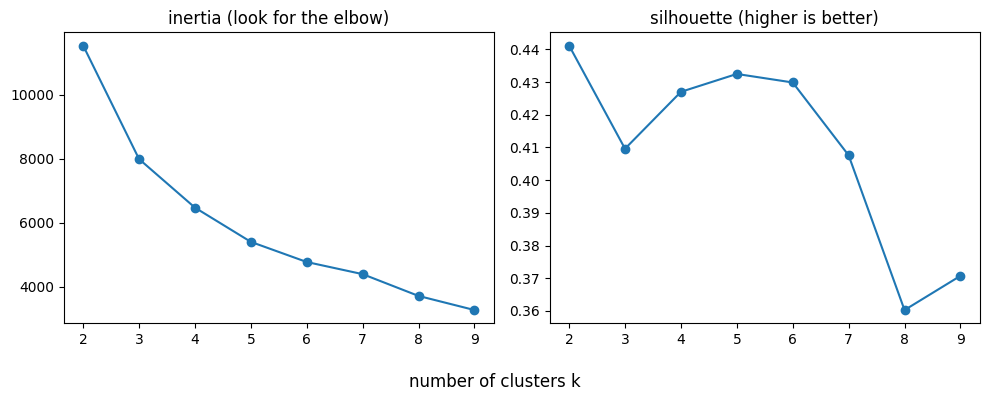

In [13]:
k_values = range(2, 10)
inertias = []
silhouettes = []

for k in k_values:
    kmeans_test = KMeans(n_clusters=k, random_state=RANDOM_SEED)
    labels_test = kmeans_test.fit_predict(features_scaled)
    inertias.append(kmeans_test.inertia_)
    silhouettes.append(silhouette_score(features_scaled, labels_test))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("inertia (look for the elbow)")
axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set_title("silhouette (higher is better)")
fig.supxlabel("number of clusters k")
fig.tight_layout()
plt.show()

#### outliers

threshold: 2.19
outliers: 71


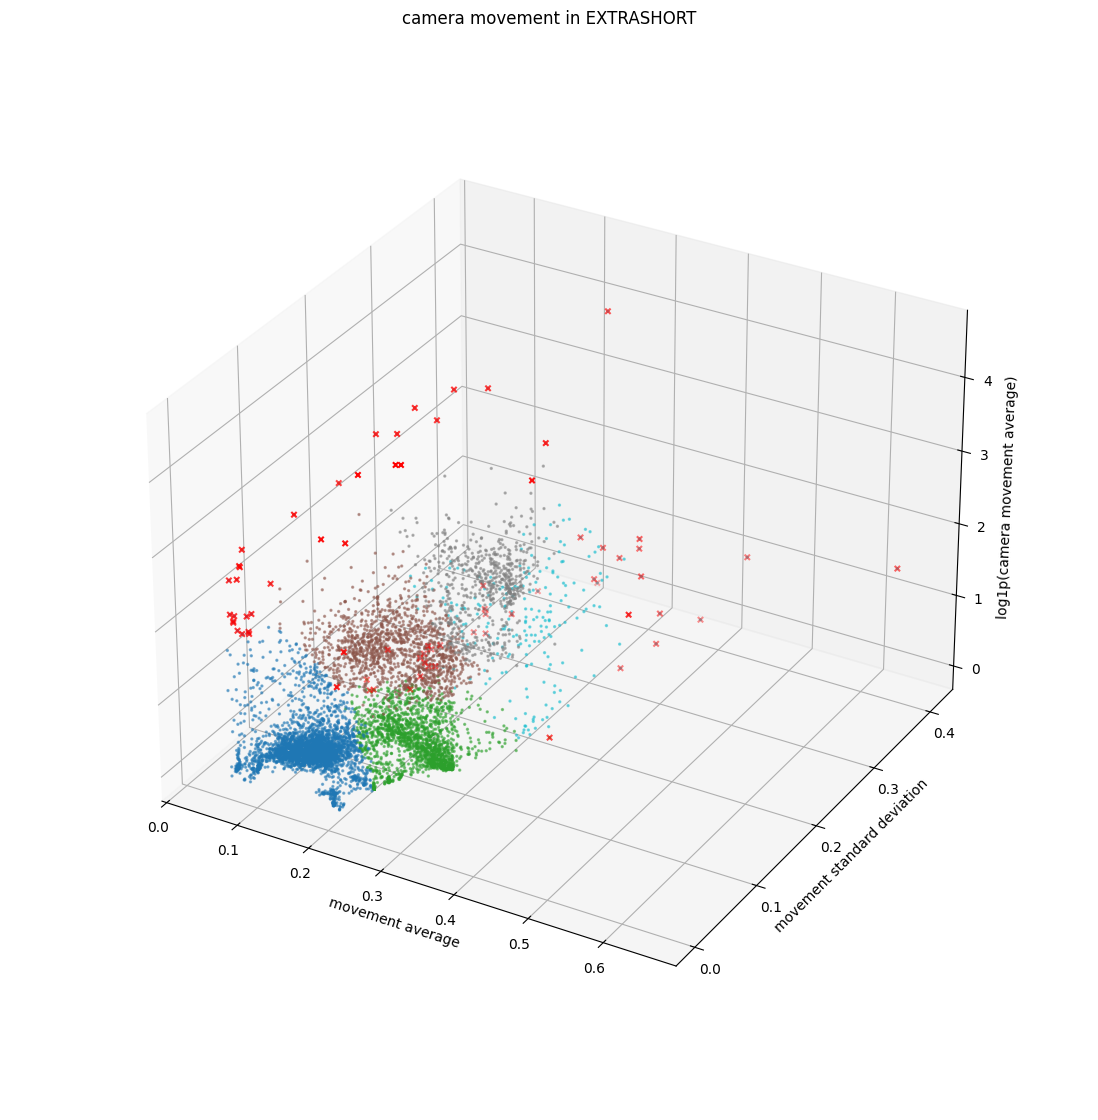

In [14]:
center_distances = kmeans.transform(features_scaled).min(axis=1)
outlier_threshold = np.percentile(center_distances, OUTLIER_PERCENTILE)
is_outlier = center_distances > outlier_threshold

print(f"threshold: {outlier_threshold:.2f}")
print(f"outliers: {is_outlier.sum()}")

outlier_rows = df_clustering_extrashort[is_outlier]

fig = plt.figure(figsize=(18, 14))
ax = fig.add_subplot(projection="3d")

ax.scatter(
    df_clustering_extrashort["movement_avg"],
    df_clustering_extrashort["movement_std"],
    df_clustering_extrashort["turn_avg_log"],
    c=cluster_labels,
    cmap="tab10",
    s=2.0,
    alpha=0.5
)

ax.scatter(
    outlier_rows["movement_avg"],
    outlier_rows["movement_std"],
    outlier_rows["turn_avg_log"],
    color="red", marker="x", s=15
)
ax.set_xlabel("movement average")
ax.set_ylabel("movement standard deviation")
ax.set_zlabel("log1p(camera movement average)")
ax.set_title("camera movement in EXTRASHORT")
ax.set_box_aspect(None, zoom=0.85)

plt.show()